# 1. Limpeza e Tratamento de Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
from sklearn.preprocessing import MinMaxScaler

import matplotlib.ticker as mtick
import matplotlib.transforms as transforms




df = pd.read_csv('Life Expectancy Data.csv')

## **Estudo do Dataset**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [ ]:
df.shape
df.head(10)

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
5,Afghanistan,2010,Developing,58.8,279.0,74,0.01,79.679367,66.0,1989,...,66.0,9.20,66.0,0.1,553.328940,2883167.0,18.4,18.4,0.448,9.2
6,Afghanistan,2009,Developing,58.6,281.0,77,0.01,56.762217,63.0,2861,...,63.0,9.42,63.0,0.1,445.893298,284331.0,18.6,18.7,0.434,8.9
7,Afghanistan,2008,Developing,58.1,287.0,80,0.03,25.873925,64.0,1599,...,64.0,8.33,64.0,0.1,373.361116,2729431.0,18.8,18.9,0.433,8.7
8,Afghanistan,2007,Developing,57.5,295.0,82,0.02,10.910156,63.0,1141,...,63.0,6.73,63.0,0.1,369.835796,26616792.0,19.0,19.1,0.415,8.4
9,Afghanistan,2006,Developing,57.3,295.0,84,0.03,17.171518,64.0,1990,...,58.0,7.43,58.0,0.1,272.563770,2589345.0,19.2,19.3,0.405,8.1


**Substituição dos valores nulos pela moda**

In [ ]:
print(df.isnull().sum())

Country                              0
Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
 BMI                                34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
 HIV/AIDS                            0
GDP                                448
Population                         652
 thinness  1-19 years               34
 thinness 5-9 years                 34
Income composition of resources    167
Schooling                          163
dtype: int64


In [ ]:
for column in df.columns:
    mode = df[column].mode()[0]
    df.fillna({column: mode}, inplace=True)

df.isnull().sum()

,0
Country,0
Year,0
Status,0
Life expectancy,0
Adult Mortality,0
infant deaths,0
Alcohol,0
percentage expenditure,0
Hepatitis B,0
Measles,0


In [ ]:
#Converter variáveis ​​categóricas para o tipo de dados apropriado

df['Country'] =df['Country'].astype('category')
df['Status'] =df['Status'].astype('category')

print(df.dtypes)

Country                            category
Year                                  int64
Status                             category
Life expectancy                     float64
Adult Mortality                     float64
infant deaths                         int64
Alcohol                             float64
percentage expenditure              float64
Hepatitis B                         float64
Measles                               int64
 BMI                                float64
under-five deaths                     int64
Polio                               float64
Total expenditure                   float64
Diphtheria                          float64
 HIV/AIDS                           float64
GDP                                 float64
Population                          float64
 thinness  1-19 years               float64
 thinness 5-9 years                 float64
Income composition of resources     float64
Schooling                           float64
dtype: object


## **Resumo de Estatísticas**

In [ ]:
df.describe().style.background_gradient(cmap='Blues')

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000,2938.000000
mean,2007.518720,69.237781,164.276378,30.303948,4.299588,738.251295,84.339687,2419.592240,38.554765,42.035739,82.656569,5.835252,82.431926,1.742103,6342.347799,9923248.812948,4.795269,4.824370,0.591880,12.043125
std,4.613841,9.510183,124.399126,117.926501,4.079052,1987.914858,23.664672,11467.272489,20.044238,160.445548,23.389352,2.426626,23.677846,5.077785,13409.380598,54075838.993817,4.413688,4.502781,0.251140,3.270983
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.000000,0.000000,3.000000,0.370000,2.000000,0.100000,1.681350,34.000000,0.100000,0.100000,0.000000,0.000000
25%,2004.000000,63.200000,73.000000,0.000000,0.470000,4.685343,82.000000,0.000000,19.400000,0.000000,78.000000,4.370000,78.000000,0.100000,190.174435,5874.250000,1.500000,1.500000,0.465000,10.300000
50%,2008.000000,72.100000,144.000000,3.000000,3.130000,64.912906,95.000000,17.000000,43.900000,4.000000,93.000000,5.540000,93.000000,0.100000,1171.983435,539357.500000,3.300000,3.300000,0.662000,12.500000
75%,2012.000000,75.600000,227.000000,22.000000,7.390000,441.534144,99.000000,360.250000,56.475000,28.000000,97.000000,7.330000,97.000000,0.800000,4779.405190,4584371.250000,7.100000,7.200000,0.772000,14.100000
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,99.000000,17.600000,99.000000,50.600000,119172.741800,1293859294.000000,27.700000,28.600000,0.948000,20.700000


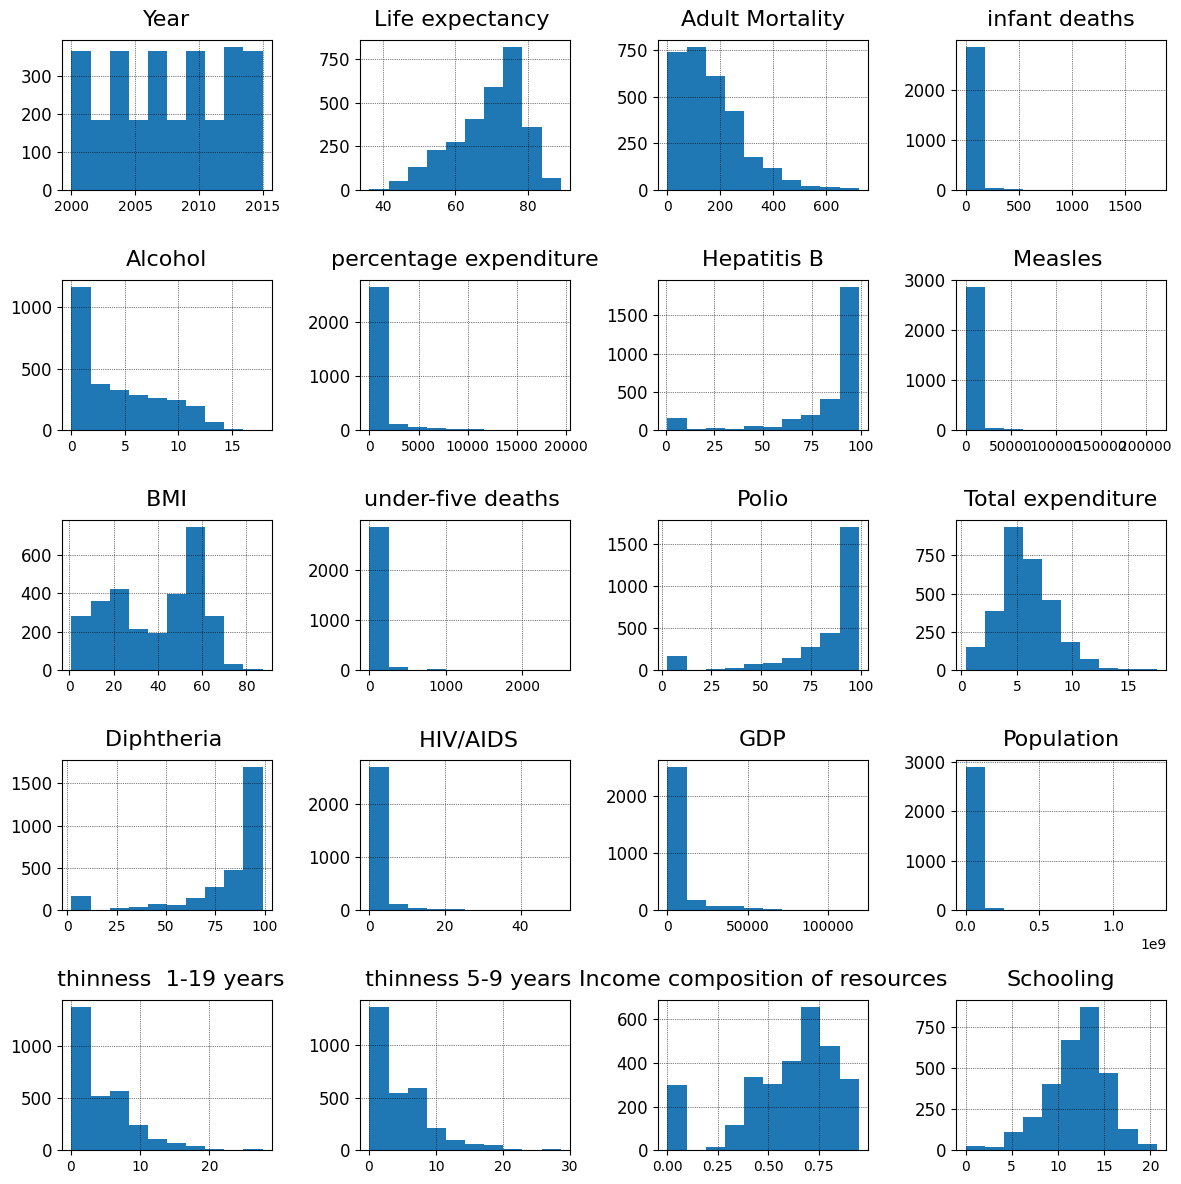

In [ ]:
df.hist(figsize=(12, 12))
#plt.title('Distribuição de Dados')
plt.tight_layout()
plt.show()

In [ ]:
unique_countries = set(df['Country'])
unique_countries

{'Afghanistan',
 'Albania',
 'Algeria',
 'Angola',
 'Antigua and Barbuda',
 'Argentina',
 'Armenia',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahamas',
 'Bahrain',
 'Bangladesh',
 'Barbados',
 'Belarus',
 'Belgium',
 'Belize',
 'Benin',
 'Bhutan',
 'Bolivia (Plurinational State of)',
 'Bosnia and Herzegovina',
 'Botswana',
 'Brazil',
 'Brunei Darussalam',
 'Bulgaria',
 'Burkina Faso',
 'Burundi',
 'Cabo Verde',
 'Cambodia',
 'Cameroon',
 'Canada',
 'Central African Republic',
 'Chad',
 'Chile',
 'China',
 'Colombia',
 'Comoros',
 'Congo',
 'Cook Islands',
 'Costa Rica',
 'Croatia',
 'Cuba',
 'Cyprus',
 'Czechia',
 "Côte d'Ivoire",
 "Democratic People's Republic of Korea",
 'Democratic Republic of the Congo',
 'Denmark',
 'Djibouti',
 'Dominica',
 'Dominican Republic',
 'Ecuador',
 'Egypt',
 'El Salvador',
 'Equatorial Guinea',
 'Eritrea',
 'Estonia',
 'Ethiopia',
 'Fiji',
 'Finland',
 'France',
 'Gabon',
 'Gambia',
 'Georgia',
 'Germany',
 'Ghana',
 'Greece',
 'Grenada',
 'Guatemala'

In [ ]:

continents = {
    'Afghanistan': 'Asia',
    'Albania': 'Europe',
    'Algeria': 'Africa',
    'Angola': 'Africa',
    'Antigua and Barbuda': 'America',
    'Argentina': 'America',
    'Armenia': 'Asia',
    'Australia': 'Oceania',
    'Austria': 'Europe',
    'Azerbaijan': 'Asia',
    'Bahamas': 'America',
    'Bahrain': 'Asia',
    'Bangladesh': 'Asia',
    'Barbados': 'America',
    'Belarus': 'Europe',
    'Belgium': 'Europe',
    'Belize': 'America',
    'Benin': 'Africa',
    'Bhutan': 'Asia',
    'Bolivia (Plurinational State of)': 'America',
    'Bosnia and Herzegovina': 'Europe',
    'Botswana': 'Africa',
    'Brazil': 'America',
    'Brunei Darussalam': 'Asia',
    'Bulgaria': 'Europe',
    'Burkina Faso': 'Africa',
    'Burundi': 'Africa',
    'Cabo Verde': 'Africa',
    'Cambodia': 'Asia',
    'Cameroon': 'Africa',
    'Canada': 'America',
    'Central African Republic': 'Africa',
    'Chad': 'Africa',
    'Chile': 'America',
    'China': 'Asia',
    'Colombia': 'America',
    'Comoros': 'Africa',
    'Congo': 'Africa',
    'Cook Islands': 'Oceania',
    'Costa Rica': 'America',
    'Croatia': 'Europe',
    'Cuba': 'America',
    'Cyprus': 'Europe',
    'Czechia': 'Europe',
    "Côte d'Ivoire": 'Africa',
    "Democratic People's Republic of Korea": 'Asia',
    'Democratic Republic of the Congo': 'Africa',
    'Denmark': 'Europe',
    'Djibouti': 'Africa',
    'Dominica': 'America',
    'Dominican Republic': 'America',
    'Ecuador': 'America',
    'Egypt': 'Africa',
    'El Salvador': 'America',
    'Equatorial Guinea': 'Africa',
    'Eritrea': 'Africa',
    'Estonia': 'Europe',
    'Ethiopia': 'Africa',
    'Fiji': 'Oceania',
    'Finland': 'Europe',
    'France': 'Europe',
    'Gabon': 'Africa',
    'Gambia': 'Africa',
    'Georgia': 'Asia',
    'Germany': 'Europe',
    'Ghana': 'Africa',
    'Greece': 'Europe',
    'Grenada': 'America',
    'Guatemala': 'America',
    'Guinea': 'Africa',
    'Guinea-Bissau': 'Africa',
    'Guyana': 'America',
    'Haiti': 'America',
    'Honduras': 'America',
    'Hungary': 'Europe',
    'Iceland': 'Europe',
    'India': 'Asia',
    'Indonesia': 'Asia',
    'Iran (Islamic Republic of)': 'Asia',
    'Iraq': 'Asia',
    'Ireland': 'Europe',
    'Israel': 'Asia',
    'Italy': 'Europe',
    'Jamaica': 'America',
    'Japan': 'Asia',
    'Jordan': 'Asia',
    'Kazakhstan': 'Asia',
    'Kenya': 'Africa',
    'Kiribati': 'Oceania',
    'Kuwait': 'Asia',
    'Kyrgyzstan': 'Asia',
    "Lao People's Democratic Republic": 'Asia',
    'Latvia': 'Europe',
    'Lebanon': 'Asia',
    'Lesotho': 'Africa',
    'Liberia': 'Africa',
    'Libya': 'Africa',
    'Lithuania': 'Europe',
    'Luxembourg': 'Europe',
    'Madagascar': 'Africa',
    'Malawi': 'Africa',
    'Malaysia': 'Asia',
    'Maldives': 'Asia',
    'Mali': 'Africa',
    'Malta': 'Europe',
    'Marshall Islands': 'Oceania',
    'Mauritania': 'Africa',
    'Mauritius': 'Africa',
    'Mexico': 'America',
    'Micronesia (Federated States of)': 'Oceania',
    'Monaco': 'Europe',
    'Mongolia': 'Asia',
    'Montenegro': 'Europe',
    'Morocco': 'Africa',
    'Mozambique': 'Africa',
    'Myanmar': 'Asia',
    'Namibia': 'Africa',
    'Nauru': 'Oceania',
    'Nepal': 'Asia',
    'Netherlands': 'Europe',
    'New Zealand': 'Oceania',
    'Nicaragua': 'America',
    'Niger': 'Africa',
    'Nigeria': 'Africa',
    'Niue': 'Oceania',
    'Norway': 'Europe',
    'Oman': 'Asia',
    'Pakistan': 'Asia',
    'Palau': 'Oceania',
    'Panama':  'America',
    'Papua New Guinea': 'Oceania',
    'Paraguay': 'America',
    'Peru': 'America',
    'Philippines': 'Asia',
    'Poland': 'Europe',
    'Portugal': 'Europe',
    'Qatar': 'Asia',
    'Republic of Korea': 'Asia',
    'Republic of Moldova': 'Europe',
    'Romania': 'Europe',
    'Russian Federation': 'Europe',
    'Rwanda': 'Africa',
    'Saint Kitts and Nevis': 'America',
    'Saint Lucia': 'America',
    'Saint Vincent and the Grenadines': 'America',
    'Samoa': 'Oceania',
    'San Marino': 'Europe',
    'Sao Tome and Principe': 'Africa',
    'Saudi Arabia': 'Asia',
    'Senegal': 'Africa',
    'Serbia': 'Europe',
    'Seychelles': 'Africa',
    'Sierra Leone': 'Africa',
    'Singapore': 'Asia',
    'Slovakia': 'Europe',
    'Slovenia': 'Europe',
    'Solomon Islands': 'Oceania',
    'Somalia': 'Africa',
    'South Africa': 'Africa',
    'South Sudan': 'Africa',
    'Spain': 'Europe',
    'Sri Lanka': 'Asia',
    'Sudan': 'Africa',
    'Suriname': 'America',
    'Swaziland': 'Africa',
    'Sweden': 'Europe',
    'Switzerland': 'Europe',
    'Syrian Arab Republic': 'Asia',
    'Tajikistan': 'Asia',
    'Thailand': 'Asia',
    'The former Yugoslav republic of Macedonia': 'Europe',
    'Timor-Leste': 'Asia',
    'Togo': 'Africa',
    'Tonga': 'Oceania',
    'Trinidad and Tobago': 'America',
    'Tunisia': 'Africa',
    'Turkey': 'Asia',
    'Turkmenistan': 'Asia',
    'Tuvalu': 'Oceania',
    'Uganda': 'Africa',
    'Ukraine': 'Europe',
    'United Arab Emirates': 'Asia',
    'United Kingdom of Great Britain and Northern Ireland': 'Europe',
    'United Republic of Tanzania': 'Africa',
    'United States of America': 'America',
    'Uruguay': 'America',
    'Uzbekistan': 'Asia',
    'Vanuatu': 'Oceania',
    'Venezuela (Bolivarian Republic of)': 'America',
    'Viet Nam': 'Asia',
    'Yemen': 'Asia',
    'Zambia': 'Africa',
    'Zimbabwe': 'Africa'
}
df["Continent"] = df["Country"].map(continents)

grouped_data = df.groupby(["Continent", "Year"]).mean(numeric_only=True)

print(grouped_data)



                Life expectancy   Adult Mortality  infant deaths   Alcohol  \
Continent Year                                                               
Africa    2000         54.720370       276.777778      49.722222  2.860926   
          2001         55.207407       277.129630      49.185185  2.842407   
          2002         55.631481       275.944444      48.611111  2.997778   
          2003         55.557407       269.370370      47.962963  2.856852   
          2004         55.925926       313.648148      47.055556  2.877593   
...                          ...              ...            ...       ...   
Oceania   2011         71.920000       129.200000       1.100000  2.803000   
          2012         71.600000       133.500000       1.100000  2.228000   
          2013         72.250000        90.500000       0.687500  1.303125   
          2014         71.970000       111.600000       1.100000  2.043000   
          2015         72.160000       140.000000       1.100000

In [ ]:
print(df.columns)  # Verifique se a coluna 'Continent' está presente


Index(['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure',
       'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population',
       ' thinness  1-19 years', ' thinness 5-9 years',
       'Income composition of resources', 'Schooling', 'Continent'],
      dtype='object')


In [ ]:
from sklearn.preprocessing import MinMaxScaler

df_normalized = df.copy()
df_normalized[df.select_dtypes(include=['float64', 'int64']).columns] = MinMaxScaler().fit_transform(df.select_dtypes(include=['float64', 'int64']))


# 2. Visualizações: Perspetiva Económica

## Como a expectativa de vida mudou ao longo do tempo em diferentes países?


### **Gráfico de linhas: evolução da expectativa de vida por continente**

In [ ]:

# Filtrar e preparar os dados
df_filtered = df[['Continent', 'Year', 'Life expectancy ', 'Status']].dropna()
df_filtered.rename(columns={'Life expectancy ': 'Life_expectancy'}, inplace=True)

# Ordenar os dados para evitar quebras nas linhas
df_filtered = df_filtered.sort_values(by=['Continent', 'Year'])

continent_colors = {
    'Africa': 'red',
    'Asia': 'blue',
    'Europe': 'green',
    'Oceania': 'purple',
    'America': 'pink'
}

fig = go.Figure()

# Adicionar uma linha para cada continente
for continent in df_filtered['Continent'].unique():
    continent_data = df_filtered[df_filtered['Continent'] == continent]
    # Calcular a expectativa de vida média por continente e ano
    continent_avg = continent_data.groupby('Year')['Life_expectancy'].mean().reset_index()

    fig.add_trace(go.Scatter(
        x=continent_avg['Year'],
        y=continent_avg['Life_expectancy'],
        mode='lines',
        name=continent,
        line=dict(color=continent_colors.get(continent, 'gray'))  # Cor específica para cada continente
    ))

fig.update_layout(
    title="Evolução da Expectativa de Vida ao Longo do Tempo por Continente",
    xaxis_title="Ano",
    yaxis_title="Expectativa de Vida (anos)",
    template="plotly_white",
    height=600,
    width=900,
    legend_title="Continentes"
)

fig.show()


### **Choropleth Map + Timeline**


In [ ]:

fig = px.choropleth(
    df,
    locations="Country",  # Localização dos países
    locationmode="country names",  # Usar os nomes dos países
    color='Life expectancy ',  # Cor baseada na expectativa de vida
    hover_name="Country",  # Mostrar o nome do país no hover
    animation_frame="Year",  # Adicionar slider para anos
    title="Expectativa de Vida por País ao Longo dos Anos",
    labels={
        "Life expectancy ": "Expectativa de Vida (anos)",
        "Year": "Ano"
    },
    template="plotly_white"
)

fig.update_layout(
    coloraxis_colorbar_title="Expectativa de Vida (anos)",
    height=600
)

fig.show()


## Qual a relação entre o PIB per capita e a expectativa de vida?

### **Butterfly Chart**

<ipython-input-82-daf5c4dd95a4>:63: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



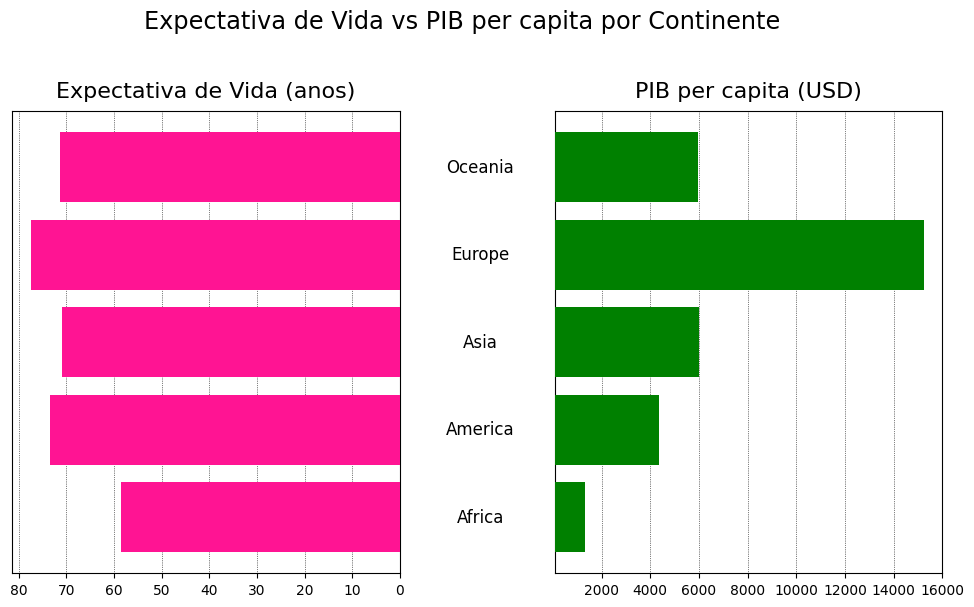

In [ ]:

def butterfly_chart(data: pd.DataFrame, title: str = None, middle_label_offset=0.01, figsize=(10, 3), wspace=0.35):
    """Gráfico tipo butterfly para comparar Expectativa de Vida e PIB per capita por continente com colunas espelhadas."""

    # Definir configurações gerais do gráfico
    plt.rcParams.update({
        'figure.facecolor': 'w',
        'font.size': 12,
        'axes.titlesize': 16,
        'xtick.labelsize': 10,
        'axes.titlepad': 10,
        'axes.grid': True,
        'grid.color': 'k',
        'grid.linestyle': ':',
        'grid.linewidth': 0.5,
    })

    # Subplot com dois eixos para gráfico lado a lado
    fig, (ax1, ax2) = plt.subplots(
        figsize=figsize,
        dpi=100,
        nrows=1,
        ncols=2,
        subplot_kw={'yticks': []},
        gridspec_kw={'wspace': wspace},
    )

    # Extrair as variáveis para o gráfico
    l1, x1 = 'Expectativa de Vida (anos)', data['Life expectancy ']  # Expectativa de Vida
    l2, x2 = 'PIB per capita (USD)', data['GDP']  # PIB per capita
    y = range(len(data))  # Posições no eixo y
    labels = data.index.tolist()  # Nomes dos continentes

    # Plotar Expectativa de Vida no lado esquerdo com rosa choque
    ax1.barh(y=y, width=x1, color='deeppink', zorder=3)  # Esperança de vida invertida para a esquerda
    ax1.set_title(l1)
    ax1.invert_xaxis()  # Inverter eixo x para o lado esquerdo

    # Plotar PIB no lado direito com verde
    ax2.barh(y=y, width=x2, color='green', zorder=3)  # PIB no lado direito, com valores positivos
    ax2.set_title(l2)

    # Forçar os limites do eixo x para que fiquem simétricos
    x_max = max(ax1.get_xlim()[0], ax2.get_xlim()[0])
    ax1.set_xlim((x_max))  # Limite do lado esquerdo
    ax2.set_xlim((x_max))  # Limite do lado direito

    # Tornar visíveis as bordas internas do eixo y
    ax1.spines['right'].set_visible(True)
    ax2.spines['left'].set_visible(True)

    # Formatando os eixos para mostrar os valores corretamente
    ax1.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(abs(x))}'))  # Expectativa de vida
    ax2.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x)}'))  # PIB

    # Adicionar os nomes dos continentes no centro
    transform = transforms.blended_transform_factory(fig.transFigure, ax1.transData)
    for i, label in enumerate(labels):
        ax1.text(0.5 + middle_label_offset, i, label, ha='center', va='center', transform=transform)

    # Título geral
    plt.suptitle(title, y=1.05, fontsize='x-large')

    plt.tight_layout()
    plt.show()

# Agrupar dados por continente e calcular médias
df_grouped = df.groupby('Continent').agg({
    'Life expectancy ': 'mean',  # Média da expectativa de vida
    'GDP': 'mean'               # Média do PIB
}).reset_index()


butterfly_chart(
    df_grouped.set_index('Continent'),  # Definindo o continente como índice
    title='Expectativa de Vida vs PIB per capita por Continente',
    figsize=(12, 6),
    wspace=0.4,
    middle_label_offset=0.015
)


### **Scatterplot: expectativa de vida vs PIB per capita**



In [ ]:

fig = px.scatter(
    df,
    x='GDP',
    y='Life expectancy ',
    color='Continent',
    size='GDP',  # Ajustar o tamanho dos pontos com base no PIB
    title="Relação entre PIB per capita e Expectativa de Vida com Tamanho de Marcador pelo PIB",
    labels={
        "GDP": "PIB per capita (USD)",
        "Life expectancy ": "Expectativa de Vida (anos)",
        "Continent": "Continente"
    },
    template="plotly_white",
    size_max=60  # Definir um tamanho máximo para os pontos
)

fig.update_layout(
    xaxis_title="PIB per capita (USD)",
    yaxis_title="Expectativa de Vida (anos)",
    legend_title="Continente",
    height=600
)

fig.show()


# 3. Visualizações: Perspetiva de Saúde


## Como os indicadores de saúde influenciam a expectativa de vida?


### **Radar**


In [ ]:

df_continent_avg = df.groupby(['Continent']).mean(numeric_only=True)[['Adult Mortality', 'infant deaths']].reset_index()

scaler = MinMaxScaler()
df_continent_avg[['Adult Mortality', 'infant deaths']] = scaler.fit_transform(
    df_continent_avg[['Adult Mortality', 'infant deaths']]
)

fig = go.Figure()

fig.add_trace(go.Scatterpolar(
    r=df_continent_avg['Adult Mortality'],
    theta=df_continent_avg['Continent'],
    fill='toself',
    name='Mortalidade Adulta',
    line_color='deeppink',
    fillcolor='rgba(255, 20, 147, 0.3)'
))

fig.add_trace(go.Scatterpolar(
    r=df_continent_avg['infant deaths'],
    theta=df_continent_avg['Continent'],
    fill='toself',
    name='Mortalidade Infantil',
    line_color='green',
    fillcolor='rgba(0, 255, 0, 0.3)'
))


fig.update_layout(
    title='Mortalidade Adulta vs Mortalidade Infantil, em média, por continente',
    polar=dict(
        radialaxis=dict(
            visible=True
        )
    ),
    legend_title='Variáveis'
)

fig.show()


### **Heatmap**


In [ ]:
import plotly.express as px

df_continent_avg = df.groupby(['Continent']).mean(numeric_only=True)[
    ['Life expectancy ', 'Adult Mortality', 'infant deaths', 'under-five deaths ', 'Alcohol',
     'Hepatitis B', 'Measles ', ' BMI ', ' HIV/AIDS']].reset_index()

df_continent_avg_normalized = df_continent_avg.drop('Continent', axis=1).apply(lambda x: (x - x.min()) / (x.max() - x.min()), axis=0).T

#criar o heatmap
fig = px.imshow(df_continent_avg_normalized,
                labels=dict(x="Continente", y="Indicador", color="Valor Normalizado"),
                x=df_continent_avg['Continent'],
                color_continuous_scale="PiYG",
                title="Heatmap: Comparação de Indicadores de Saúde por Continente (Valores Normalizados)",
                zmin=0, zmax=1)

fig.update_layout(coloraxis_colorbar=dict(
    tickvals=[0, 0.2, 0.4, 0.6, 0.8, 1],
    ticktext=["Mínimo", "Baixo", "Médio-baixo", "Médio", "Alto", "Máximo"],
    title="Escala de Intensidade",
))


fig.show()


##  Como a expectativa de vida se altera entre regiões com altos e baixos níveis de consumo de álcool?


### **Gráfico de Eixos Duplos**

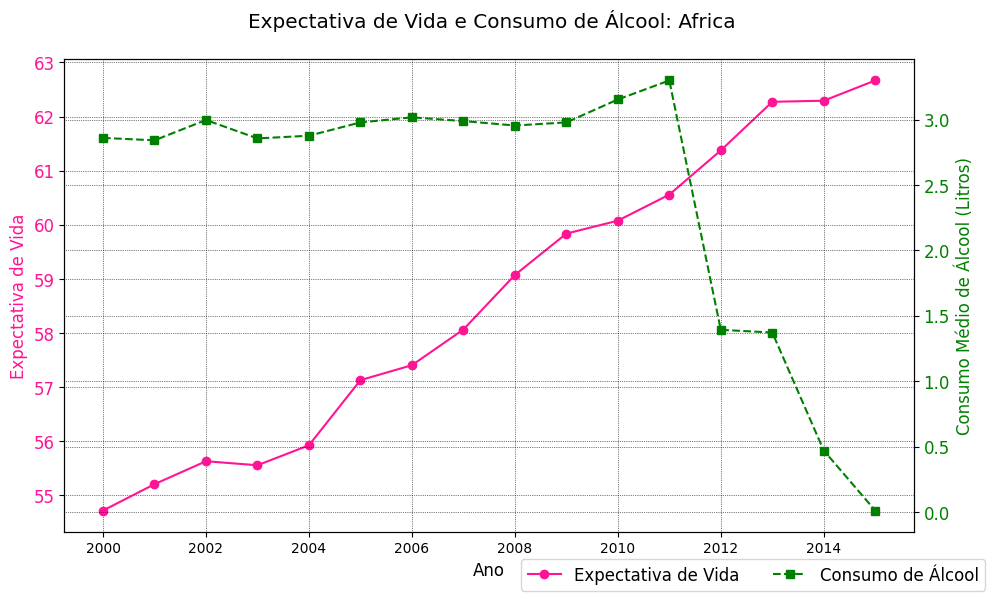

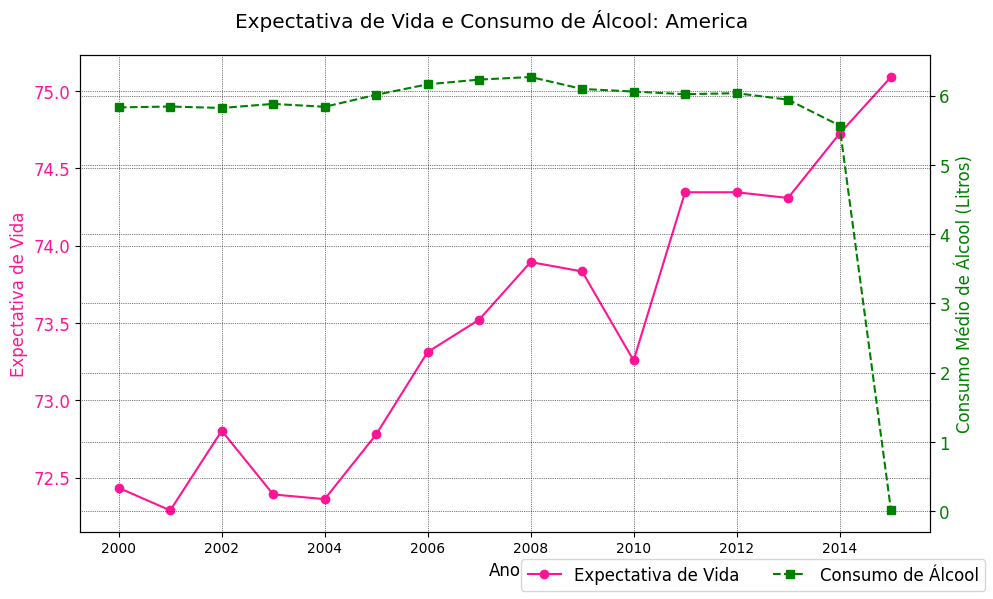

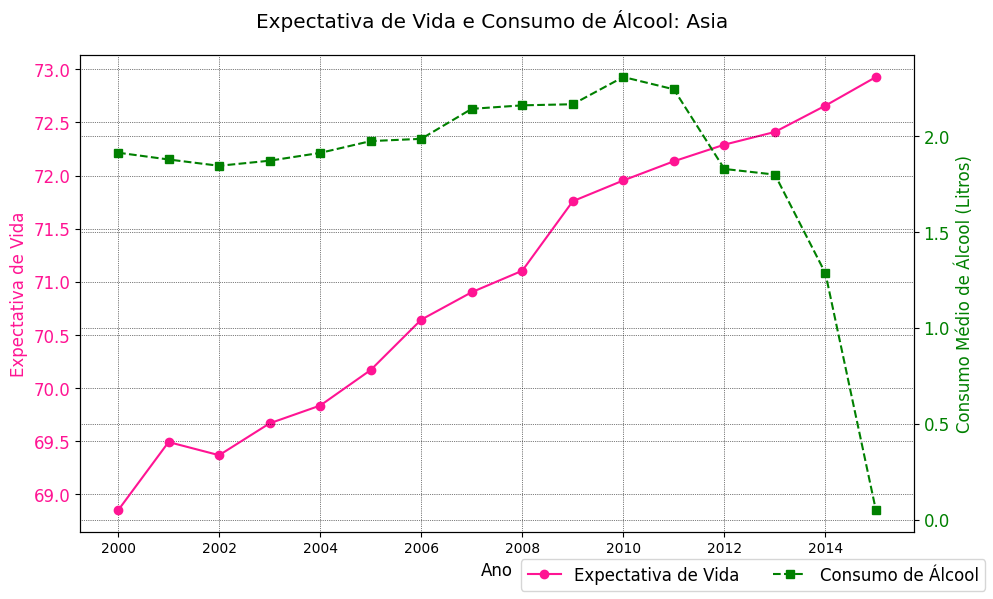

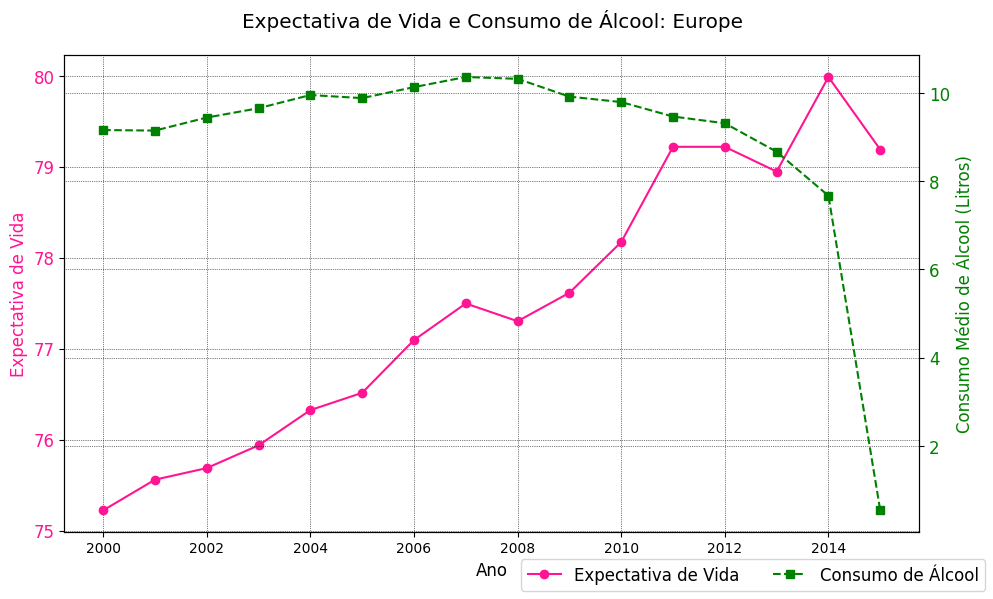

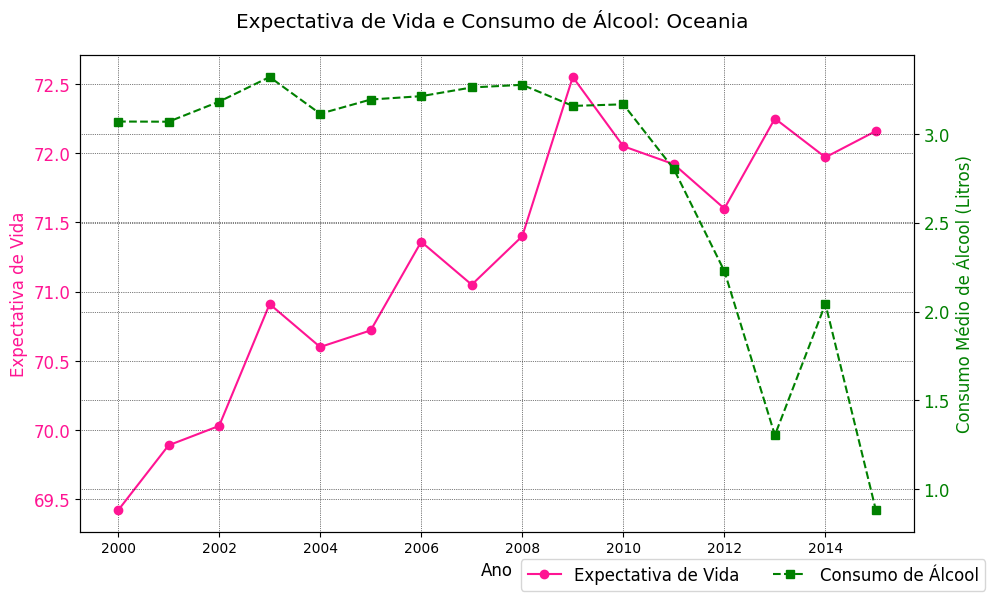

In [ ]:
df_grouped = df.groupby(['Year', 'Continent']).agg({
    'Life expectancy ': 'mean',
    'Alcohol': 'mean'
}).reset_index()


continentes = df_grouped['Continent'].unique()

for continente in continentes:
    df_continente = df_grouped[df_grouped['Continent'] == continente]

    fig, ax1 = plt.subplots(figsize=(10, 6))

    #expectativa de vida
    ax1.plot(df_continente['Year'], df_continente['Life expectancy '], color='deeppink', marker='o', label='Expectativa de Vida')
    ax1.set_xlabel('Ano')
    ax1.set_ylabel('Expectativa de Vida', color='deeppink')
    ax1.tick_params(axis='y', labelcolor='deeppink')

    #consumo de álcool
    ax2 = ax1.twinx()
    ax2.plot(df_continente['Year'], df_continente['Alcohol'], color='green', marker='s', linestyle='--', label='Consumo de Álcool')
    ax2.set_ylabel('Consumo Médio de Álcool (Litros)', color='green')
    ax2.tick_params(axis='y', labelcolor='green')


    fig.suptitle(f'Expectativa de Vida e Consumo de Álcool: {continente}')
    fig.tight_layout()  # Ajustar layout para evitar sobreposição


    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    fig.legend(handles1 + handles2, labels1 + labels2, loc='lower right', ncol=2)

    plt.show()

### **Gráfico de Linhas**

In [ ]:


alcool_threshold = df['Alcohol'].median()
df['Nível de Álcool'] = df['Alcohol'].apply(lambda x: 'Alto' if x > alcool_threshold else 'Baixo')

df_grouped = df.groupby(['Year', 'Continent', 'Nível de Álcool']).agg({
    'Life expectancy ': 'mean',   #expectativa de vida
    'Adult Mortality': 'mean',    #mortalidade adulta
    'infant deaths': 'mean',      #mortes infantis
    'under-five deaths ': 'mean', #mortes abaixo de 5 anos
    'Alcohol': 'mean'             #consumo de álcool
}).reset_index()


continentes = df_grouped['Continent'].unique()

for continente in continentes:
    df_continente = df_grouped[df_grouped['Continent'] == continente]

    fig = px.line(df_continente,
                  x='Year',
                  y='Life expectancy ',
                  color='Nível de Álcool',
                  line_group='Nível de Álcool',
                  title=f"Tendências de Saúde e Expectativa de Vida - {continente}",
                  labels={'Life expectancy ': 'Expectativa de Vida', 'Year': 'Ano', 'Nível de Álcool': 'Nível de Consumo de Álcool'},
                  template='plotly_white')
    fig.update_layout(
                  legend_title_text='Nível de Álcool',
                  legend=dict(
                  x=1,  # posição horizontal da legenda
                  y=1,  # posição vertical da legenda
                  xanchor='left',
                  yanchor='top',
                  title_font=dict(size=12),
                  font=dict(size=10)
        ),
        margin=dict(l=40, r=40, t=50, b=40)  # ajusta as margens do gráfico
    )

    fig.show()